# GARCH(1,1) on daily Bitcoin returns

This notebook documents the GARCH(1,1) model behind CryptoQuantLab's Risk tab: the data, the model and its likelihood, how the parameters are estimated, whether the estimator recovers known parameters, what the fitted model says about Bitcoin, and what the diagnostics leave unexplained.

The reference implementation is [`cql_validation/garch.py`](../cql_validation/garch.py). The TypeScript model in [`backend/src/models/garch.ts`](../../backend/src/models/garch.ts) is tested against fixtures written from it: log-likelihood within 1e-4, parameters within 1e-3, and the conditional volatility path within 0.1% relative.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox

sys.path.insert(0, str(Path.cwd().parent))
from cql_validation import garch, garch_diagnostics, returns, var

plt.rcParams.update({"figure.figsize": (9, 3.4), "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:.6g}")

btc = pd.read_csv("../data/bitcoin_usd_daily.csv", parse_dates=["date"])
prices = btc["price_usd"].to_numpy()
dates = btc["date"]
periods_per_year = returns.periods_per_year(btc["timestamp_ms"].to_numpy())
print(f"{len(prices)} daily closes, {dates.iloc[0]:%Y-%m-%d} to {dates.iloc[-1]:%Y-%m-%d}; {periods_per_year:.2f} observations per year")

364 daily closes, 2025-10-23 to 2026-10-21; 365.25 observations per year


## 1. Data

Daily closes are CoinGecko's 00:00 UTC snapshots for one year. GARCH works on log returns $r_t = \ln(P_t / P_{t-1})$. Before modelling, the returns' summary statistics show why a constant-volatility model is a poor description: the excess kurtosis is far from the normal distribution's 0, and Jarque-Bera rejects normality.

In [2]:
r = returns.log_returns(prices)
m = returns.moments(r)
jb = stats.jarque_bera(r)
pd.DataFrame(
    {
        "value": [
            len(r),
            m.mean * periods_per_year,
            m.standard_deviation,
            m.standard_deviation * np.sqrt(periods_per_year),
            m.skewness,
            m.excess_kurtosis,
            jb.statistic,
            jb.pvalue,
        ]
    },
    index=[
        "returns",
        "mean (annualized)",
        "standard deviation (daily)",
        "standard deviation (annualized)",
        "skewness (G1)",
        "excess kurtosis (G2)",
        "Jarque-Bera statistic",
        "Jarque-Bera p-value",
    ],
)

,value
returns,363
mean (annualized),-0.26179
standard deviation (daily),0.0229995
standard deviation (annualized),0.439556
skewness (G1),-0.245028
excess kurtosis (G2),6.80729
Jarque-Bera statistic,682.038
Jarque-Bera p-value,7.89381e-149


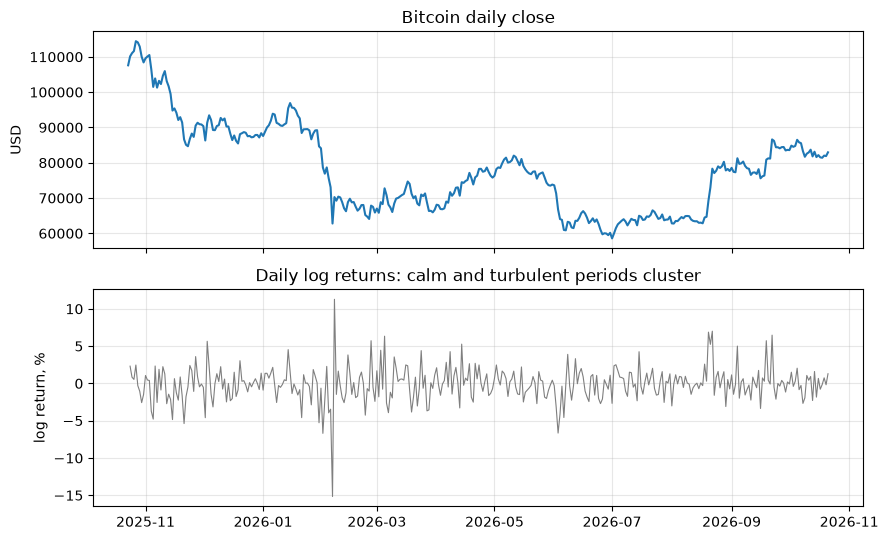

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
ax1.plot(dates, prices, color="tab:blue")
ax1.set_ylabel("USD")
ax1.set_title("Bitcoin daily close")
ax2.plot(dates[1:], r * 100, color="tab:gray", linewidth=0.8)
ax2.set_ylabel("log return, %")
ax2.set_title("Daily log returns: calm and turbulent periods cluster")
fig.tight_layout()

## 2. Model and likelihood

Returns are demeaned by their sample mean, $\varepsilon_t = r_t - \bar r$, and the conditional variance follows

$$h_t = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,h_{t-1}, \qquad \omega > 0,\ \alpha, \beta \ge 0,\ \alpha + \beta < 1.$$

With Gaussian innovations $\varepsilon_t = \sqrt{h_t}\,z_t$, $z_t \sim N(0, 1)$, the log-likelihood conditional on $h_0$ is

$$\ln L(\omega, \alpha, \beta) = -\tfrac{1}{2}\sum_{t=1}^{n-1}\left(\ln 2\pi + \ln h_t + \frac{\varepsilon_t^2}{h_t}\right).$$

Two conventions matter when comparing implementations. Here $h_0$ is the sample variance and the $t = 0$ term is left out. The `arch` package instead backcasts the pre-sample variance and includes every term, so its estimates differ slightly on the same data.

The unconditional variance is $\bar\sigma^2 = \omega / (1 - \alpha - \beta)$. A shock's effect on the variance decays by the persistence $\alpha + \beta$ each day, giving a half-life of $\ln 0.5 / \ln(\alpha + \beta)$.

## 3. Estimation

The reference maximises the likelihood in percent units, so the three parameters have similar scales. It starts SLSQP from a grid of starting points under the stationarity constraint, then polishes the best result with Nelder-Mead. The TypeScript model uses Nelder-Mead on $(\ln\omega, \ln\alpha, \ln\beta)$ from a single start; the tests check it reaches the same maximum.

The likelihood surface below fixes $\omega$ by variance targeting, $\omega = (1 - \alpha - \beta)\,s^2$, so the picture shows how sharply the data pin down $\alpha$ and $\beta$. The estimate is marked.

In [4]:
fit = garch.fit(prices)
check = garch.arch_cross_check(prices, horizon=30)
pd.DataFrame(
    {
        "reference": [fit.omega, fit.alpha, fit.beta, fit.alpha + fit.beta, fit.log_likelihood],
        "arch": [check["omega"], check["alpha"], check["beta"], check["alpha"] + check["beta"], np.nan],
        "arch std. error": [check["stdErrors"]["omega"], check["stdErrors"]["alpha"], check["stdErrors"]["beta"], np.nan, np.nan],
    },
    index=["ω", "α", "β", "α + β", "log-likelihood"],
)

,reference,arch,arch std. error
ω,9.42705e-05,9.42665e-05,5.07176e-05
α,0.190901,0.190397,0.0843418
β,0.635485,0.635531,0.109016
α + β,0.826386,0.825929,NaN
log-likelihood,874.689,NaN,NaN


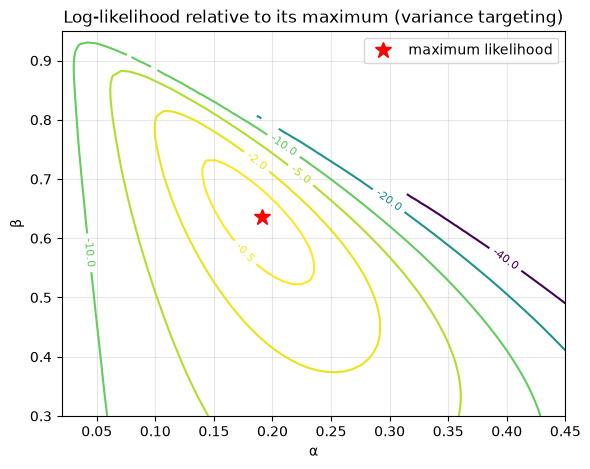

In [5]:
resid = garch.demeaned_log_returns(prices)
s2 = float(np.mean(resid**2))
alphas = np.linspace(0.02, 0.45, 60)
betas = np.linspace(0.30, 0.95, 60)
surface = np.full((len(betas), len(alphas)), np.nan)
for i, b in enumerate(betas):
    for j, a in enumerate(alphas):
        if a + b < 0.995:
            surface[i, j] = garch.log_likelihood((1 - a - b) * s2, a, b, resid, s2)

fig, ax = plt.subplots(figsize=(6.5, 5))
levels = np.nanmax(surface) - np.array([40, 20, 10, 5, 2, 0.5])
contour = ax.contour(alphas, betas, surface, levels=levels, cmap="viridis")
ax.clabel(contour, fmt=lambda v: f"{v - np.nanmax(surface):.1f}", fontsize=8)
ax.plot(fit.alpha, fit.beta, "r*", markersize=12, label="maximum likelihood")
ax.set_xlabel("α")
ax.set_ylabel("β")
ax.set_title("Log-likelihood relative to its maximum (variance targeting)")
ax.legend()

## 4. Does the estimator recover known parameters?

A year of daily data is a small sample for GARCH. To see how well the estimator works at this size, the cell below simulates 30 paths of 1,000 days from a GARCH(1,1) with known parameters, fits each, and compares the estimates with the truth.

In [6]:
true = {"omega": 4.5e-5, "alpha": 0.10, "beta": 0.85}
rng = np.random.default_rng(20261026)


def simulate(n, omega, alpha, beta):
    h, prev, out = omega / (1 - alpha - beta), 0.0, np.empty(n)
    for t in range(n):
        h = omega + alpha * prev**2 + beta * h
        prev = np.sqrt(h) * rng.standard_normal()
        out[t] = prev
    return 100 * np.exp(np.concatenate([[0.0], np.cumsum(out)]))


estimates = pd.DataFrame([vars(garch.fit(simulate(1000, **true)))  for _ in range(30)])[["omega", "alpha", "beta"]]
estimates["persistence"] = estimates["alpha"] + estimates["beta"]
truth = pd.Series({**true, "persistence": true["alpha"] + true["beta"]})
pd.DataFrame(
    {
        "true": truth,
        "mean estimate": estimates.mean(),
        "bias": estimates.mean() - truth,
        "std. dev.": estimates.std(ddof=1),
        "RMSE": np.sqrt(((estimates - truth) ** 2).mean()),
    }
)

,true,mean estimate,bias,std. dev.,RMSE
omega,4.5e-05,5.14513e-05,6.45134e-06,2.34534e-05,2.39447e-05
alpha,0.1,0.100603,0.000603491,0.0230172,0.0226384
beta,0.85,0.840411,-0.00958852,0.0442787,0.0445779
persistence,0.95,0.941015,-0.00898503,0.0318498,0.032578


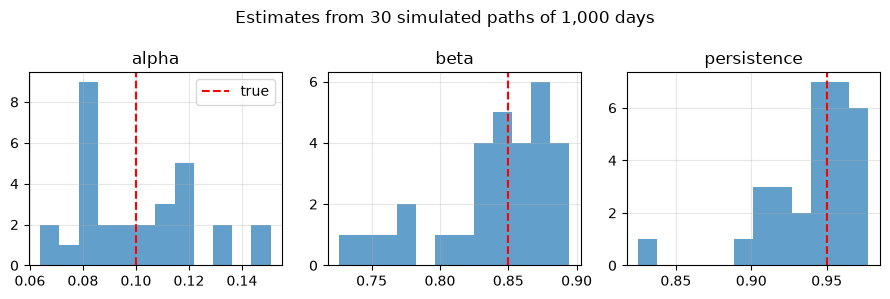

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, name in zip(axes, ["alpha", "beta", "persistence"]):
    ax.hist(estimates[name], bins=12, color="tab:blue", alpha=0.7)
    ax.axvline(truth[name], color="red", linestyle="--", label="true")
    ax.set_title(name)
axes[0].legend()
fig.suptitle("Estimates from 30 simulated paths of 1,000 days")
fig.tight_layout()

In [8]:
cv = estimates[["alpha", "beta", "persistence"]].std(ddof=1) / truth[["alpha", "beta", "persistence"]]
print(f"coefficient of variation: α {cv['alpha']:.1%}, β {cv['beta']:.1%}, α + β {cv['persistence']:.1%}")
print(f"correlation of the α and β estimates: {estimates['alpha'].corr(estimates['beta']):.2f}")

coefficient of variation: α 23.0%, β 5.2%, α + β 3.4%
correlation of the α and β estimates: -0.72


The estimator is close to unbiased at this sample size. Relative to its size, $\alpha$ is the least precise estimate and the persistence $\alpha + \beta$ the most: $\alpha$ and $\beta$ are strongly negatively correlated across samples, along the ridge visible in the likelihood surface above, so their errors partly cancel in the sum. That matters for interpretation, because the half-life and the forecasts depend mainly on the persistence.

## 5. The fitted model on Bitcoin

In [9]:
annualize = np.sqrt(periods_per_year) * 100
persistence = fit.alpha + fit.beta
pd.DataFrame(
    {
        "value": [
            persistence,
            np.log(0.5) / np.log(persistence),
            np.sqrt(fit.omega / (1 - persistence)) * annualize,
            np.sqrt(fit.variance[-1]) * annualize,
            np.sqrt(fit.next_variance) * annualize,
        ]
    },
    index=[
        "persistence α + β",
        "half-life (days)",
        "long-run volatility (% a year)",
        "latest conditional volatility (% a year)",
        "next-day forecast (% a year)",
    ],
)

,value
persistence α + β,0.826386
half-life (days),3.63488
long-run volatility (% a year),44.5339
latest conditional volatility (% a year),32.3638
next-day forecast (% a year),33.7712


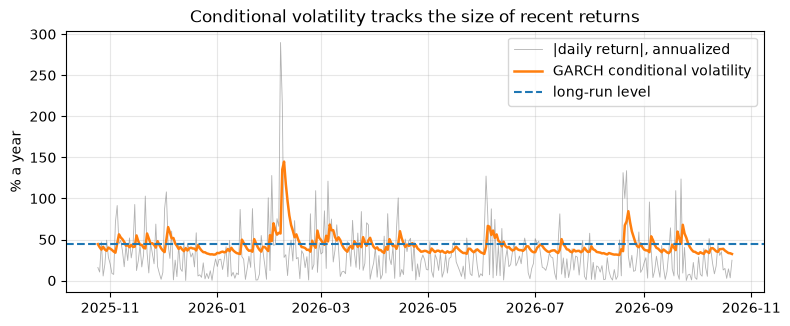

In [10]:
fig, ax = plt.subplots()
ax.plot(dates[2:], np.abs(r[1:]) * annualize, color="tab:gray", linewidth=0.6, alpha=0.6, label="|daily return|, annualized")
ax.plot(dates[2:], np.sqrt(fit.variance) * annualize, color="tab:orange", linewidth=1.8, label="GARCH conditional volatility")
ax.axhline(np.sqrt(fit.omega / (1 - persistence)) * annualize, color="tab:blue", linestyle="--", label="long-run level")
ax.set_ylabel("% a year")
ax.set_title("Conditional volatility tracks the size of recent returns")
ax.legend(loc="upper right")

## 6. Diagnostics

If the model is adequate, the standardized residuals $z_t = \varepsilon_t / \sqrt{h_t}$ should be serially uncorrelated, their squares should show no remaining volatility clustering, and for the Gaussian likelihood to be correctly specified they should be normal. Ljung-Box at several lags tests the first two, on the raw returns for comparison.

In [11]:
z = garch_diagnostics.standardized_residuals(prices, fit)
rows = {}
for name, series in {"r": resid[1:], "r²": resid[1:] ** 2, "z": z, "z²": z**2}.items():
    lb = acorr_ljungbox(series, lags=[5, 10, 20])
    rows[name] = lb["lb_pvalue"].to_numpy()
pd.DataFrame(rows, index=["p-value, 5 lags", "p-value, 10 lags", "p-value, 20 lags"]).T

,"p-value, 5 lags","p-value, 10 lags","p-value, 20 lags"
r,0.719199,0.182058,0.256843
r²,8.80774e-10,4.08219e-08,2.1264e-05
z,0.736198,0.62108,0.581688
z²,0.415469,0.369496,0.665438


In [12]:
jb_z = stats.jarque_bera(z)
info = garch_diagnostics.information_criteria(fit, len(z))
pd.DataFrame(
    {"value": [stats.kurtosis(z, fisher=True, bias=False), jb_z.statistic, jb_z.pvalue, info["aic"], info["bic"]]},
    index=["excess kurtosis of z", "Jarque-Bera statistic", "Jarque-Bera p-value", "AIC (k = 4)", "BIC (k = 4)"],
)

,value
excess kurtosis of z,2.61755
Jarque-Bera statistic,100.545
Jarque-Bera p-value,1.46883e-22
AIC (k = 4),-1741.38
BIC (k = 4),-1725.81


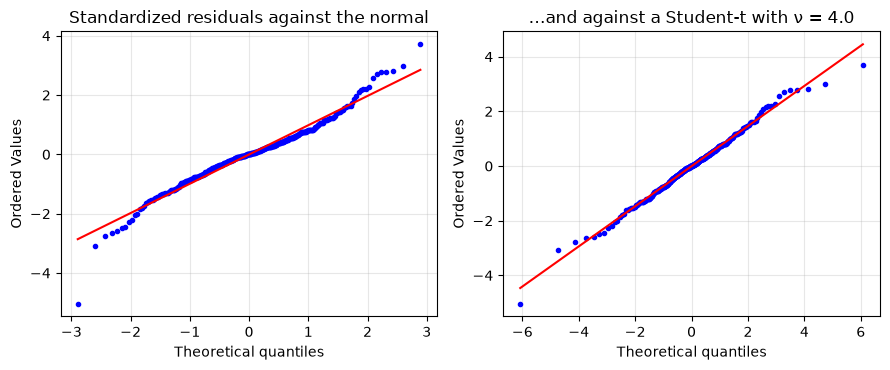

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))
stats.probplot(z, dist="norm", plot=ax1)
ax1.set_title("Standardized residuals against the normal")
t_dof = stats.t.fit(z)[0]
stats.probplot(z, dist=stats.t, sparams=(t_dof,), plot=ax2)
ax2.set_title(f"…and against a Student-t with ν = {t_dof:.1f}")
for ax in (ax1, ax2):
    ax.get_lines()[0].set_markersize(3)
fig.tight_layout()

GARCH removes the volatility clustering: the Ljung-Box tests reject strongly on the squared returns and not on the squared standardized residuals. It does not make the residuals normal. Their excess kurtosis stays well above zero, Jarque-Bera rejects, and the QQ plot shows the tails bending away from the normal line while following a Student-t far more closely. The volatility dynamics are captured; the Gaussian likelihood is not quite right.

## 7. Forecasts

The variance forecast $k$ days ahead decays from the one-step-ahead variance to the long-run level, $h_{T+k} = \bar\sigma^2 + (\alpha + \beta)^{k-1}(h_{T+1} - \bar\sigma^2)$. The Risk tab reports the volatility of the average daily variance over 1, 7 and 30 days.

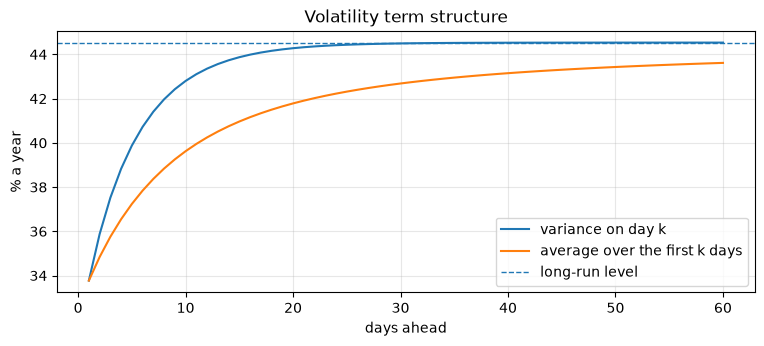

In [14]:
horizon = np.arange(1, 61)
point = np.array([garch.forecast_variance(fit, k) for k in horizon])
average = np.cumsum(point) / horizon
fig, ax = plt.subplots()
ax.plot(horizon, np.sqrt(point) * annualize, label="variance on day k")
ax.plot(horizon, np.sqrt(average) * annualize, label="average over the first k days")
ax.axhline(np.sqrt(fit.omega / (1 - persistence)) * annualize, color="tab:blue", linestyle="--", linewidth=1, label="long-run level")
ax.set_xlabel("days ahead")
ax.set_ylabel("% a year")
ax.set_title("Volatility term structure")
ax.legend()

## 8. Limitations

- **Gaussian errors.** The residual kurtosis says a Student-t or skewed-t likelihood would fit better. The Risk tab's GARCH-filtered VaR avoids the issue by drawing tomorrow's shape from the residuals themselves.
- **Symmetric response.** GARCH(1,1) treats falls and rises alike; GJR-GARCH or EGARCH would test for leverage effects.
- **Sample size.** One year of daily data identifies the persistence well, but $\alpha$ and $\beta$ individually much less so, as the simulation shows.
- **Daily closes only.** Intraday data would allow realized-variance measures and range-based estimators, which are far less noisy than squared daily returns.

## References

- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, 50(4), 987–1007.
- Jarque, C. M. and Bera, A. K. (1980). Efficient tests for normality, homoscedasticity and serial independence of regression residuals. *Economics Letters*, 6(3), 255–259.
- Ljung, G. M. and Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika*, 65(2), 297–303.
- Sheppard, K. *arch*: autoregressive conditional heteroskedasticity models in Python. https://github.com/bashtage/arch